In [6]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
data = pd.read_csv(r"C:\Users\ASUS\OneDrive\Documents\Bank_Customer_Churn_(U).csv")

In [8]:
data

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42.0,2,0.00,1,1,1.0,101348.88,1
1,15647311,608,Spain,Female,41.0,1,83807.86,1,0,1.0,112542.58,0
2,15619304,502,France,Female,42.0,8,159660.80,3,1,0.0,113931.57,1
3,15701354,699,France,Female,39.0,1,0.00,2,0,0.0,93826.63,0
4,15737888,850,Spain,Female,43.0,2,125510.82,1,1,1.0,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,15606229,771,France,Male,39.0,5,0.00,2,1,0.0,96270.64,0
9996,15569892,516,NaN,Male,35.0,10,57369.61,1,1,NaN,101699.77,0
9997,15584532,709,France,NaN,36.0,7,0.00,1,0,1.0,42085.58,1
9998,15682355,772,Germany,Male,42.0,3,75075.31,2,1,0.0,92888.52,1


In [9]:
# QUE - 1 
# 1.Fill all missing values in the Country column with the name of the country in which you are currently residing.

In [10]:
data.isnull().any()

customer_id         False
credit_score        False
country              True
gender               True
age                  True
tenure              False
balance              True
products_number     False
credit_card         False
active_member        True
estimated_salary     True
churn               False
dtype: bool

In [11]:
data["country"].isnull().sum()

np.int64(999)

In [12]:
data["country"]=data["country"].fillna("India")

In [13]:
data["country"].isnull().sum()

np.int64(0)

In [14]:
# que 2
# Identify the total number of female records in the dataset. Compare the count of males and females, and fill all missing values in the Gender column with the gender that has the higher count.

In [15]:
females_only = data[data['gender'] == 'Female']
female_count = len(females_only)
print("Total number of female records:", female_count)

Total number of female records: 4080


In [16]:
males_only = data[data['gender'] == 'Male']
male_count = len(males_only)
print("Total number of male records:", male_count)


Total number of male records: 4922


In [17]:
if male_count > female_count:
    higher_gender = "Male"
else:
    higher_gender = "Female"

print("The gender with the higher count is:", higher_gender)


The gender with the higher count is: Male


In [18]:
data['gender'] = data['gender'].fillna(higher_gender)


In [19]:
data["gender"].isnull().any()

np.False_

In [20]:
# 3.Analyze the Age column, calculate the average age, and fill all missing age values using this average. Ensure that the age values are stored as integers (no decimal values).

In [21]:
data["age"].mean()

np.float64(38.87931608748751)

In [22]:
data["age"] = data["age"].fillna(38.87931608748751)

In [23]:
data["age"].isnull().any()

np.False_

In [24]:
data["age"]=data["age"].astype(int)

In [25]:
data["age"]

0       42
1       41
2       42
3       39
4       43
        ..
9995    39
9996    35
9997    36
9998    42
9999    28
Name: age, Length: 10000, dtype: int64

In [26]:
# 4.Handle missing values in the Balance column as follows:
#Fill the first 500 missing values with the average balance,
#Fill the next 500 missing values with the maximum balance,
#Fill the remaining missing values with 0.
#Ensure the balance values contain exactly 2 decimal places.

In [27]:
data["balance"].isnull().sum()

np.int64(1018)

In [28]:
data["balance"].mean()

np.float64(76555.61364952126)

In [29]:
data["balance"]= data["balance"].fillna(76555.61364952126,limit=500)

In [30]:
data["balance"].max()

250898.09

In [31]:
data["balance"]=data["balance"].fillna(250898.09,limit=500)

In [32]:
data["balance"] = data["balance"].fillna(0)

In [33]:
data["balance"].round(2)

0            0.00
1        83807.86
2       159660.80
3            0.00
4       125510.82
          ...    
9995         0.00
9996     57369.61
9997         0.00
9998     75075.31
9999    130142.79
Name: balance, Length: 10000, dtype: float64

In [34]:
data["balance"]

0            0.00
1        83807.86
2       159660.80
3            0.00
4       125510.82
          ...    
9995         0.00
9996     57369.61
9997         0.00
9998     75075.31
9999    130142.79
Name: balance, Length: 10000, dtype: float64

In [35]:
# 5.For the Active_Member column, fill missing values such that 50% of them are assigned 1 (active) and the remaining 50% are assigned 0 (inactive).

In [36]:
data["active_member"].isnull().sum()

np.int64(1028)

In [37]:
1028/2

514.0

In [38]:
data["active_member"] = data["active_member"].fillna(1,limit=514)

In [39]:
data["active_member"] = data["active_member"].fillna(0)

In [40]:
# 6.Calculate the average value of the Estimated_Salary column and fill all missing salary values with this average, ensuring the values have exactly 2 decimal places.

In [41]:
data["estimated_salary"].mean()

np.float64(100162.82140075657)

In [42]:
data["estimated_salary"]= data["estimated_salary"].fillna(100162.82140075657)

In [43]:
data["estimated_salary"] = data["estimated_salary"].round(2)

In [44]:
data["estimated_salary"]

0       101348.88
1       112542.58
2       113931.57
3        93826.63
4        79084.10
          ...    
9995     96270.64
9996    101699.77
9997     42085.58
9998     92888.52
9999     38190.78
Name: estimated_salary, Length: 10000, dtype: float64

In [45]:
data.isnull().any()

customer_id         False
credit_score        False
country             False
gender              False
age                 False
tenure              False
balance             False
products_number     False
credit_card         False
active_member       False
estimated_salary    False
churn               False
dtype: bool

In [46]:
data[["customer_id","credit_score","balance","products_number","credit_card","active_member","estimated_salary","churn"]].to_csv("Account_Fact.csv",index=False)

In [47]:
pwd

'C:\\Users\\ASUS\\anaconda3'

In [48]:
data[["customer_id","country","gender","age","tenure"]].to_csv("Customer_Dim.csv",index=False)

In [49]:
pwd

'C:\\Users\\ASUS\\anaconda3'

In [50]:
data.to_csv("Account_Fact(F).csv",index=False)

In [51]:
pwd

'C:\\Users\\ASUS\\anaconda3'

# ML STARTS FROM HERE

In [1]:
# Q1. Load the cleaned Bank Customer dataset. Identify the Type of ML Problem.
# Select 'Churn' as target variable, and print the shape of X and y.

In [75]:
data = pd.read_csv(r"C:\\Users\\ASUS\\anaconda3\Account_Fact(F).csv")

In [76]:
data.isnull().any()

customer_id         False
credit_score        False
country             False
gender              False
age                 False
tenure              False
balance             False
products_number     False
credit_card         False
active_member       False
estimated_salary    False
churn               False
dtype: bool

In [77]:
data

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1.0,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1.0,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0.0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0.0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1.0,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,15606229,771,France,Male,39,5,0.00,2,1,0.0,96270.64,0
9996,15569892,516,India,Male,35,10,57369.61,1,1,0.0,101699.77,0
9997,15584532,709,France,Male,36,7,0.00,1,0,1.0,42085.58,1
9998,15682355,772,Germany,Male,42,3,75075.31,2,1,0.0,92888.52,1


In [78]:
x = data.drop("churn",axis=1)

In [79]:
y = data["churn"]

In [80]:
print(x.shape)
print(y.shape)

(10000, 11)
(10000,)


In [81]:
# Q2. Identify categorical columns, apply Encoding techniques (if necessary, perform Standard Scaling on numerical features.

In [82]:
X = data.drop(['churn', 'customer_id'], axis=1)
y = data['churn']

In [83]:
categorical_col = ['country', 'gender']
categorical_col

['country', 'gender']

In [84]:
numerical_col = ['credit_score', 'age', 'tenure', 'balance', 'products_number', 'estimated_salary']
numerical_col

['credit_score',
 'age',
 'tenure',
 'balance',
 'products_number',
 'estimated_salary']

In [85]:
X = pd.get_dummies(X, columns=categorical_cols)
print("\nShape of X after encoding:", X.shape)


Shape of X after encoding: (10000, 14)


In [86]:
from sklearn.preprocessing import StandardScaler

In [87]:
scaller = StandardScaler()

In [90]:
X[numerical_col] = scaller.fit_transform(X[numerical_col])

In [91]:
X.head()

,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,country_France,country_Germany,country_India,country_Spain,gender_Female,gender_Male
0,-0.326221,0.322752,-1.041760,-1.210221,-0.911583,1,1.0,0.021742,True,False,False,False,True,False
1,-0.440036,0.222143,-1.387538,-0.018865,-0.911583,0,1.0,0.226941,False,False,False,True,True,False
2,-1.536794,0.322752,1.032908,1.059410,2.527057,1,0.0,0.252403,True,False,False,False,True,False
3,0.501521,0.020927,-1.387538,-1.210221,0.807737,0,0.0,-0.116152,True,False,False,False,True,False
4,2.063884,0.423360,-1.041760,0.573957,-0.911583,1,1.0,-0.386406,False,False,False,True,True,False


In [92]:
#Q.3.Plot churn distribution. Analyze the relationship between CreditScore, Age, and Balance with churn

In [101]:
import seaborn as sns
import matplotlib.pyplot as ply

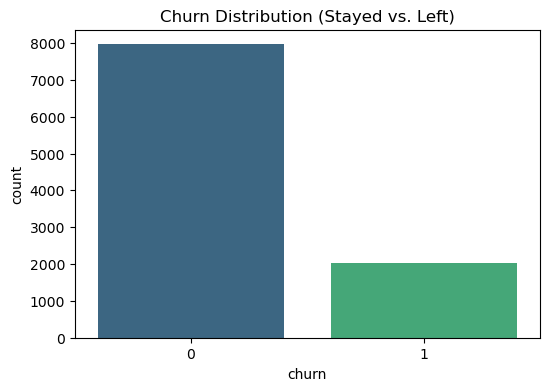

In [125]:
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='churn', palette='viridis')
plt.title('Churn Distribution (Stayed vs. Left)');

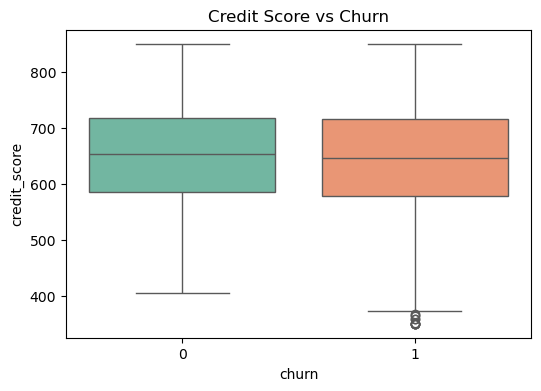

In [126]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='churn', y='credit_score', data=data, palette='Set2')
plt.title('Credit Score vs Churn');

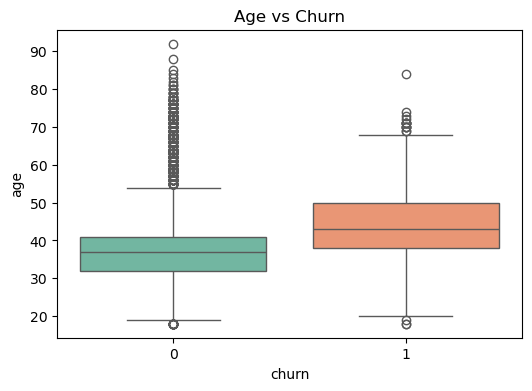

In [127]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='churn', y='age', data=data, palette='Set2')
plt.title('Age vs Churn')
plt.savefig('age_churn.png')

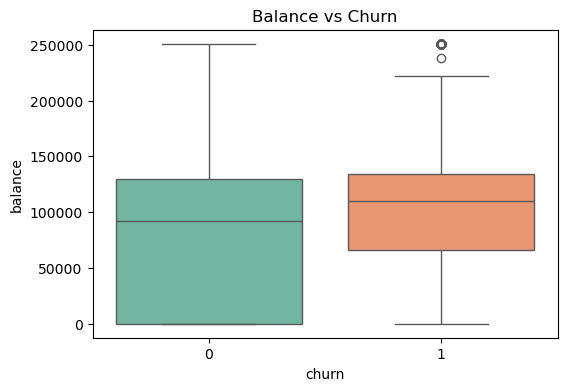

In [124]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='churn', y='balance', data=data, palette='Set2')
plt.title('Balance vs Churn');

In [123]:
import warnings
warnings.filterwarnings("ignore")

In [128]:
#Q.4 Split the dataset into training and testing sets. Train a SVM model and display accuracy Score, Confusion Matrix, Classification
#Report..

In [129]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [131]:
X = data.drop(['customer_id', 'churn'], axis=1)
y = data['churn']

In [132]:
le = LabelEncoder()
X['gender'] = le.fit_transform(X['gender'])
X['country'] = le.fit_transform(X['country'])

In [133]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [134]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [135]:
svm_model = SVC(kernel='rbf', random_state=42)
svm_model.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [136]:
y_pred = svm_model.predict(X_test)

In [138]:
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")


Accuracy Score: 0.8530


In [140]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Confusion Matrix:
[[1572   35]
 [ 259  134]]


In [141]:

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.98      0.91      1607
           1       0.79      0.34      0.48       393

    accuracy                           0.85      2000
   macro avg       0.83      0.66      0.70      2000
weighted avg       0.85      0.85      0.83      2000



In [142]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [144]:
X = data.drop(['customer_id', 'churn'], axis=1)
y = data['churn']

In [145]:
le = LabelEncoder()
X['gender'] = le.fit_transform(X['gender'])
X['country'] = le.fit_transform(X['country'])

In [146]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [147]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

In [148]:
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [149]:
y_pred_rf = rf_model.predict(X_test)

In [150]:
print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")


Random Forest Accuracy: 0.8550


In [151]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))



Confusion Matrix:
[[1537   70]
 [ 220  173]]


In [152]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.96      0.91      1607
           1       0.71      0.44      0.54       393

    accuracy                           0.85      2000
   macro avg       0.79      0.70      0.73      2000
weighted avg       0.84      0.85      0.84      2000



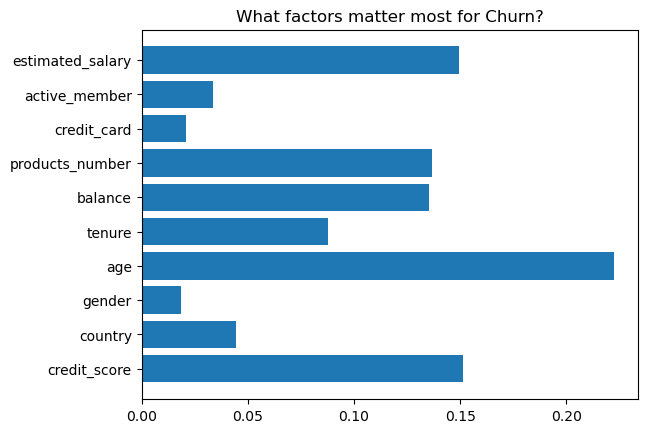

In [153]:
import matplotlib.pyplot as plt

importances = rf_model.feature_importances_
feature_names = X.columns
plt.barh(feature_names, importances)
plt.title("What factors matter most for Churn?")
plt.show()

In [ ]:
#Q5. Train a Random Forest Classifier on the same data and predict Churn,find - accuracy Score, Confusion Matrix, Classification
#Report.

In [154]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [156]:
X = data.drop(['customer_id', 'churn'], axis=1) 
y = data['churn']

In [157]:
le = LabelEncoder()
X['gender'] = le.fit_transform(X['gender'])
X['country'] = le.fit_transform(X['country'])

In [158]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [159]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [160]:
y_pred = rf_model.predict(X_test)

In [161]:
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")


Accuracy Score: 0.8550


In [162]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))



Confusion Matrix:
[[1537   70]
 [ 220  173]]


In [163]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.96      0.91      1607
           1       0.71      0.44      0.54       393

    accuracy                           0.85      2000
   macro avg       0.79      0.70      0.73      2000
weighted avg       0.84      0.85      0.84      2000

